In [1]:
%pip install opencv-python

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [3]:
img = cv2.imread("low_contrast_image.png", cv2.IMREAD_GRAYSCALE)

Text(0.5, 1.0, 'Original Image (low contrast)')

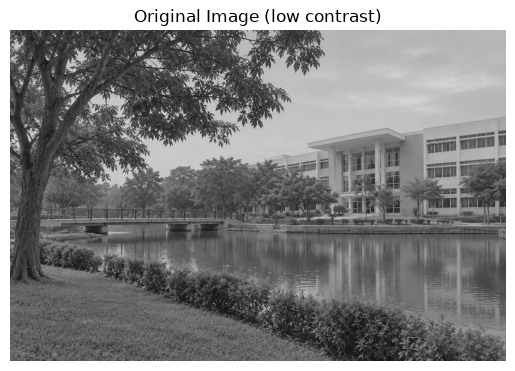

In [4]:
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.title("Original Image (low contrast)")

Compute the histogram in mannual way: Numpy's histogram function 

In [5]:
histogram, bin_edgs = np.histogram(img.flatten(), bins =256, range=(0,256))  # 0 to 255 pixel

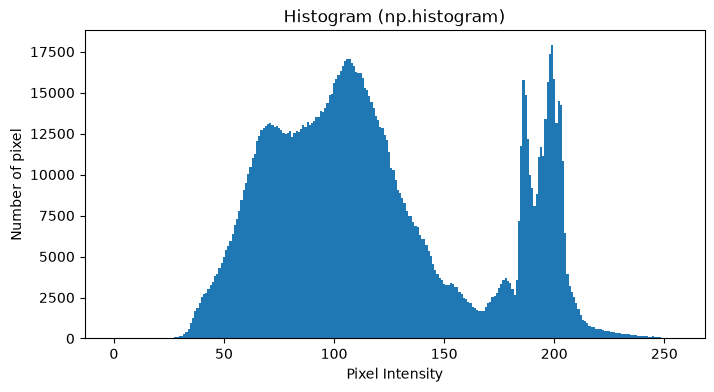

In [6]:
plt.figure(figsize=(8,4))
plt.bar(range(256), histogram, width=1)
plt.title("Histogram (np.histogram)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of pixel")
plt.show()

x axis - pixel intensity, from blac to white   
Y axis - Number of pixel in each intensity  
Tall peaks - Many pixel has those intensity value  
value concentrated on the left - The image is generally dark
value concentraed on the right - The image is generally white

In [7]:
print("Most common intensity value : ",np.argmax(histogram))
print("Number of the pixel at the intensity : ",histogram.max())

Most common intensity value :  199
Number of the pixel at the intensity :  17897


Compute the histogram using open cv build-in cv2.clacHist function

In [10]:
histogram_cv2 = cv2.calcHist([img], [0], None, [256], [0,256])

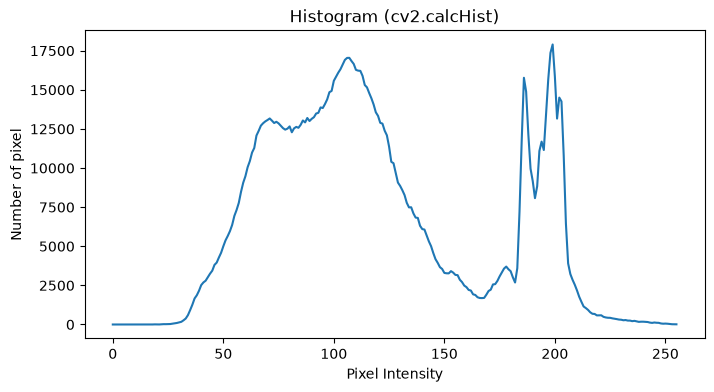

In [11]:
plt.figure(figsize=(8,4))
plt.plot(histogram_cv2)
plt.title("Histogram (cv2.calcHist)")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of pixel")
plt.show()

Histogram Equalization : mannual way

In [12]:
cdf = histogram.cumsum()
cdf_normalized = cdf * 255 / cdf[-1]

In [22]:
#mapps each original pixel intensity to its corresponding normalized CDF value
equalized_mannual = np.interp(img.flatten(), np.arange(256), cdf_normalized)
#Reshape 1D array
equalized_mannual = equalized_mannual.reshape(img.shape)
equalized_mannual = equalized_mannual.astype(np.uint8)

(np.float64(-0.5), np.float64(1535.5), np.float64(1023.5), np.float64(-0.5))

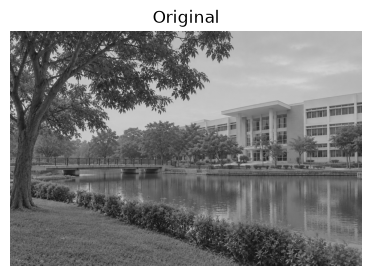

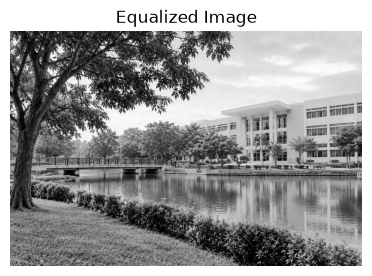

In [23]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.figure(figsize=(10,5))
plt.subplot(1,2,2)
plt.imshow(equalized_mannual, cmap="gray")
plt.title("Equalized Image")
plt.axis("off")

Histogram Equalized usins cv2

In [28]:
equalized_cv2 = cv2.equalizeHist(img)

(np.float64(-0.5), np.float64(1535.5), np.float64(1023.5), np.float64(-0.5))

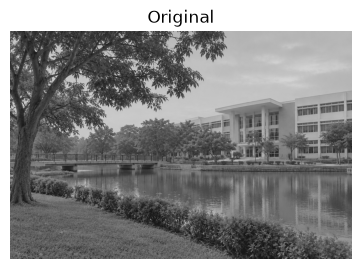

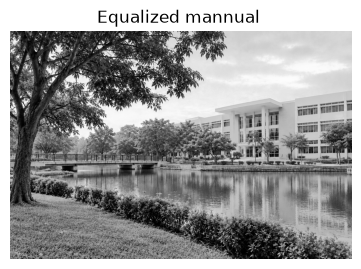

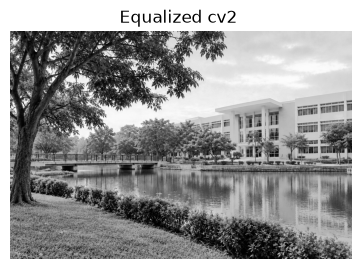

In [29]:
plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.figure(figsize=(15,4))
plt.subplot(1,3,2)
plt.imshow(equalized_mannual, cmap="gray")
plt.title("Equalized mannual ")
plt.axis("off")

plt.figure(figsize=(15,4))
plt.subplot(1,3,3)
plt.imshow(equalized_cv2, cmap="gray")
plt.title("Equalized cv2 ")
plt.axis("off")

In [37]:
hist_mannual_eq, bin_edgs = np.histogram(equalized_mannual.flatten(), bins =256, range=(0,256))
hist_cv2_eq, bin_edgs = np.histogram(equalized_cv2.flatten(), bins =256, range=(0,256))

Text(0.5, 1.0, 'Histogram CV2')

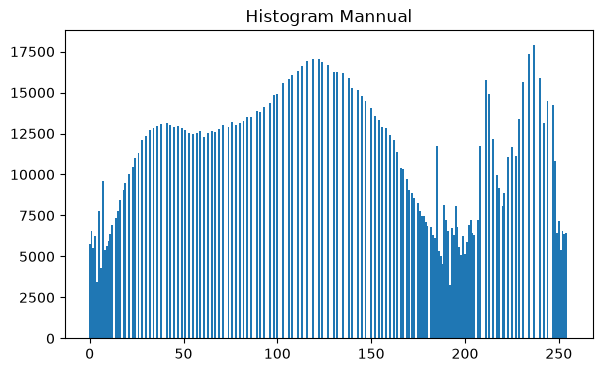

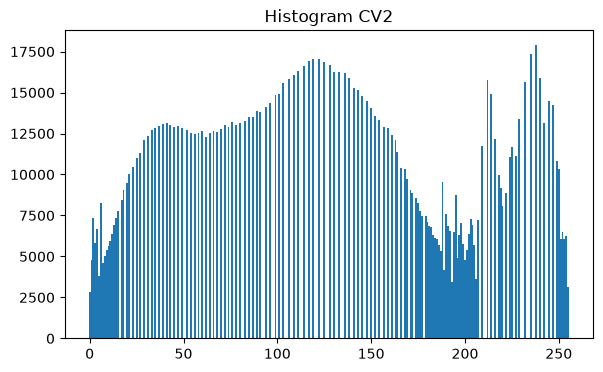

In [41]:
plt.figure(figsize=(15,4))
plt.subplot(1,2,1)
plt.bar(range(256), hist_mannual_eq, width=1)
plt.title("Histogram Mannual")

plt.figure(figsize=(15,4))
plt.subplot(1,2,2)
plt.bar(range(256), hist_cv2_eq, width=1)
plt.title("Histogram CV2")

